# Assignment 4 – Response to weather: single-storey two-zone office building (Chur)

**Team:** _Valerio Paganini_

This notebook simulates the building of Assignment 1 ([Assignment1_Model.ipynb](Assignment1_Model.ipynb)) with the
weather of Chur for one year. It uses the matrices $A$, $G$, $C$ and the state-space representation of Assignment 2
([Assignment2_SteadyState.ipynb](Assignment2_SteadyState.ipynb)); the time step follows from Assignment 3
([Assignment3_StepResponse.ipynb](Assignment3_StepResponse.ipynb)).

Content, as in the list of the assignment:

1. start and end time,
2. inputs: weather data, solar irradiance on the walls, resampling, other inputs (internal gains, set-points),
   input vector in time,
3. initial conditions,
4. integration in time (P-controller of Assignments 1–3),
5. plots and discussion,
6. other controllers: dead-band controller and model predictive control (MPC),
7. discussion.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
import dm4bem
from IPython.utils import io

with io.capture_output():                   # model (Assignment 1) and state space (Assignment 2), outputs not shown
    %run Assignment2_SteadyState.ipynb

states = np.flatnonzero(np.diag(C))         # nodes with capacity = state variables
bT, fQ = np.flatnonzero(b_ptr), np.flatnonzero(f_ptr)
jb = {k: j for j, k in enumerate(bT)}                   # branch with temperature source -> column of u
jf = {i: len(bT) + j for j, i in enumerate(fQ)}         # node with flow-rate source -> column of u
print(f'{len(states)} state variables, {len(bT)} + {len(fQ)} = {len(u_names)} inputs, outputs θ{air1}, θ{air2}')

72 state variables, 20 + 28 = 48 inputs, outputs θ71, θ144


## 1 Start and end time

One year of the typical weather year of Chur (TMYx 2004–2018, hypothesis 4). The year 2023 is used for the time
axis (it starts on a Sunday). The heavy concrete has time constants of up to 18 days (Assignment 3), so the
simulation starts 30 days earlier with the weather of the last 30 days of the year (warm-up, assumption); the
warm-up is not counted in the results.

The time step is 15 min with the implicit Euler method. The explicit method would need $\Delta t$ < 16 s
because of the P-controller (Assignment 3); the implicit method is stable for any time step. The error of
15 min is checked in section 5.

In [2]:
year, dt = 2023, 900                        # time axis; s, time step (implicit Euler)
start, end = f'{year}-01-01 00:00', f'{year}-12-31 23:45'
warmup = 30                                  # d, warm-up before the start (assumption)
print(f'{start} to {end}, Δt = {dt / 60:.0f} min, warm-up {warmup} d')

2023-01-01 00:00 to 2023-12-31 23:45, Δt = 15 min, warm-up 30 d


## 2 Inputs

### Weather data and solar irradiance on the walls

`dm4bem.read_epw` reads the weather file; `dm4bem.sol_rad_tilt_surf` gives the direct, diffuse and reflected
irradiance on each surface (azimuth 0 = south, west positive; albedo 0.2, assumption). Two corrections:

- **Time.** `read_epw` labels each hourly value with the start of its hour; `sol_rad_tilt_surf` calculates the
  position of the sun at the end of the hour (`minute + 60`) in clock time. The middle of the hour in solar time is
  $0.5\,\text{h} + (15° \cdot 1 - 9.53°)/15°\,\text{h} = 0.86$ h (52 min) earlier for Chur (UTC+1, longitude
  9.53° E; equation of time neglected). The time passed to `sol_rad_tilt_surf` is shifted by this amount; without
  it the east façade would get 37 % less and the west façade 35 % more direct radiation in the year.
- **Ground reflection.** `sol_rad_tilt_surf` multiplies the radiation reflected by the ground with
  $1 - \cos\beta / 2$; the view factor of a surface with slope $\beta$ to the ground is $(1 - \cos\beta)/2$
  (Duffie & Beckman), so the reflected part is corrected (it was twice too large on the façades).

In [3]:
weather, meta = dm4bem.read_epw('daten/CHE_GR_Chur.067860_TMYx.2004-2018.epw', coerce_year=year)
weather = weather[['temp_air', 'dir_n_rad', 'dif_h_rad']]
albedo = 0.2
surfaces = {'S': (90, 0), 'E': (90, -90), 'W': (90, 90), 'N': (90, 180), 'roof': (0, 0)}   # slope, azimuth
shift = pd.Timedelta(hours=0.5 + (15 * meta['TZ'] - meta['longitude']) / 15)   # see the first point above
w_sun = weather.copy()
w_sun.index = w_sun.index - shift
E = {}
for o, (slope, azimuth) in surfaces.items():
    rad = dm4bem.sol_rad_tilt_surf(w_sun, {'slope': slope, 'azimuth': azimuth, 'latitude': meta['latitude']},
                                   albedo)
    rad.index = weather.index
    cb = np.cos(np.radians(slope))
    rad['reflected'] *= ((1 - cb) / 2) / (1 - cb / 2)         # view factor to the ground (see above)
    E[o] = rad.sum(axis=1)
weather = pd.DataFrame({'T_o': weather['temp_air'], **{f'E_{o}': e for o, e in E.items()}})
weather.index = weather.index.tz_localize(None)
print(f'latitude {meta["latitude"]}°, T_o mean {weather["T_o"].mean():.1f} °C, '
      f'min {weather["T_o"].min():.1f} °C, max {weather["T_o"].max():.1f} °C')
(weather.filter(like='E_').sum() / 1000).round(0).rename('solar irradiation, kWh/(m²·a)').to_frame().T

latitude 46.8703°, T_o mean 10.4 °C, min -11.2 °C, max 31.7 °C


,E_S,E_E,E_W,E_N,E_roof
"solar irradiation, kWh/(m²·a)",1138.0,732.0,829.0,468.0,1449.0


### Resampling and warm-up

The hourly weather is resampled to the time step by linear interpolation; the last 30 days of the year are put in
front as warm-up.

In [4]:
pre = weather.loc[weather.index[-1] - pd.Timedelta(days=warmup):].iloc[1:].copy()
pre.index = pre.index - pd.Timedelta(days=365)                 # last 30 days, one year earlier
w = pd.concat([pre, weather]).resample(f'{dt}s').interpolate()
w = w.loc[:end]
t = w.index
n = len(t)
k0 = t.get_loc(pd.Timestamp(start))                            # first time step of the year
print(f'{n} time steps ({k0} of warm-up), {t[0]} to {t[-1]}')

37917 time steps (2880 of warm-up), 2022-12-02 00:00:00 to 2023-12-31 23:00:00


### Other inputs

**Internal gains** (hypothesis 9; SIA 2024 room type 3.01, assumption): occupancy Monday–Friday 07:00–18:00.
Occupants 84 W per person at 14 m² per person and equipment 11 W/m², each with its hourly profile on working days
and an annual factor of 0.8 (holidays, absence); equipment at least 30 % (stand-by), also at the weekend. Lighting
9.72 W/m² during occupancy, with a constant factor such that the annual energy is 13.45 kWh/m². All gains are
convective, on the air node.

**Set-points** (hypothesis 12): heating 21 °C and cooling 26 °C during occupancy, 18 °C and 28 °C otherwise.

**Basement** (hypothesis 5): $T_{bsmt} = 20 - 0.7\,(20 - T_{o,24h})$ with the 24-hour mean of $T_o$.

**Solar radiation** (hypothesis 8; values: assumption):

| Quantity | Value |
|---|---|
| absorptivity façade / roof | 0.5 / 0.6 |
| glazing: transmitted / absorbed in the glass | 0.40 / 0.20 (g ≈ 0.5 with the part of the absorbed radiation that goes inside) |
| reduction for horizon, reveals and angle of incidence $F_{sol}$ | 0.65 |
| frame (no solar gain) | 20 % of the window |
| external blinds closed: factor on transmitted and absorbed | 0.20 ($g_{tot} \approx 0.10$) |
| blinds closed if | irradiance on the façade > 200 W/m² and 24-hour mean of $T_o$ > 12 °C (summer) |
| transmitted radiation | 50 % on the floor, 50 % on the inner surfaces of walls, roof and interior wall by area (not on the windows) |

The rule for the blinds depends only on the weather, so all inputs are known in advance (also for the MPC).

In [5]:
p_persons = np.array([0, 0, 0, 0, 0, 0, 0, 0.2, 0.6, 1, 1, 0.8, 0.4, 0.6, 1, 0.8, 0.6, 0.2, 0, 0, 0, 0, 0, 0])
p_equip = np.array([0.3] * 8 + [0.6, 0.8, 1, 0.8, 0.4, 0.6, 1, 0.8, 0.6] + [0.3] * 7)
f_year, f_standby = 0.8, 0.3                                     # annual factor, stand-by share of equipment

workday = t.dayofweek < 5
h = t.hour + t.minute / 60
occupied = workday & (h >= 7) & (h < 18)
q_pers = np.where(workday, p_persons[t.hour] * f_year, 0) * 84 / 14          # W/m²
q_equip = np.where(workday, np.maximum(p_equip[t.hour] * f_year, f_standby), f_standby) * 11
f_light = 13.45e3 / (9.72 * occupied[k0:].sum() * dt / 3600)                  # annual energy 13.45 kWh/m²
q_light = np.where(occupied, f_light, 0) * 9.72
q_int = q_pers + q_equip + q_light                                            # W/m² of floor

T_h = np.where(occupied, 21.0, 18.0)                             # °C, heating set-point
T_c = np.where(occupied, 26.0, 28.0)                             # °C, cooling set-point
T_o24 = w['T_o'].rolling('24h', min_periods=1).mean().to_numpy()
T_bsmt = 20 - 0.7 * (20 - T_o24)

alpha_wall, alpha_roof = 0.5, 0.6
tau_g, alpha_g, F_sol, F_c = 0.40, 0.20, 0.65, 0.20
blind = {o: (w[f'E_{o}'].to_numpy() > 200) & (T_o24 > 12) for o in ('S', 'E', 'W', 'N')}
print(f'internal gains: mean {q_int[k0:].mean():.1f} W/m², max {q_int.max():.1f} W/m², '
      f'{q_int[k0:].sum() * dt / 3.6e6:.1f} kWh/(m²·a); lighting factor {f_light:.2f}')
print('blinds closed (h/a): ' + ', '.join(f'{o} {blind[o][k0:].sum() * dt / 3600:.0f}' for o in blind))

internal gains: mean 6.7 W/m², max 18.3 W/m², 58.7 kWh/(m²·a); lighting factor 0.48
blinds closed (h/a): S 1208, E 863, W 984, N 270


### Input vector in time

The input $u$ has one row per time step and the 48 columns of Assignment 2: first the temperature sources $b_T$
(branches), then the flow-rate sources $f_Q$ (nodes). Node numbers of zone 1 (zone 2: + 73): outer surfaces
$\theta_0, \theta_{15}, \theta_{30}$ (walls S, E, W), $\theta_{45}$ (roof); glass $\theta_{13}, \theta_{28},
\theta_{43}$; inner surfaces $\theta_{12}, \theta_{27}, \theta_{42}$ (walls), $\theta_{57}$ (roof),
$\theta_{70}$ (floor); interior wall $\theta_{146}$ (zone 1 side), $\theta_{154}$ (zone 2 side); air
$\theta_{71}$. The set-points $T_{sp}$ are given by the controller in the time loop.

In [6]:
U = np.zeros((n, len(u_names)))
for k in bT:                                                     # temperature sources
    U[:, jb[k]] = {'T_o': w['T_o'].to_numpy(), 'T_bsmt': T_bsmt}.get(src[k], 0.0)
j_sp = [jb[k] for k in k_ctrl]                                   # columns of T_sp,1 and T_sp,2

Q_sol = {}                                                       # W, transmitted solar radiation per zone
for z, n0, o1, iw in ((1, 0, 'S', 146), (2, 73, 'N', 154)):
    Q_t = np.zeros(n)
    for o, size, k_out, k_g in ((o1, 'long', 0, 13), ('E', 'short', 15, 28), ('W', 'short', 30, 43)):
        E_o = w[f'E_{o}'].to_numpy()
        S_g = S_win[size] * (1 - frame)                          # glass area
        shade = np.where(blind[o], F_c, 1.0)
        U[:, jf[n0 + k_out]] += alpha_wall * S_wall[size] * E_o                 # Φo, outer wall surface
        U[:, jf[n0 + k_g]] += alpha_g * F_sol * shade * S_g * E_o               # Φa, glass
        Q_t += tau_g * F_sol * shade * S_g * E_o
    U[:, jf[n0 + 45]] += alpha_roof * S_plan * w['E_roof'].to_numpy()           # Φo, roof
    inner = {n0 + 12: S_wall['long'], n0 + 27: S_wall['short'], n0 + 42: S_wall['short'],
             n0 + 57: S_plan, iw: S_iw}                                         # inner surfaces except the floor
    U[:, jf[n0 + 70]] += 0.5 * Q_t                                              # Φi, floor
    for node, S in inner.items():
        U[:, jf[node]] += 0.5 * Q_t * S / sum(inner.values())                   # Φi, other inner surfaces
    U[:, jf[n0 + 71]] += S_plan * q_int                                         # internal gains, air
    Q_sol[z] = Q_t
U = pd.DataFrame(U, index=t, columns=u_names)
U.loc[f'{year}-07-17':f'{year}-07-17 23:45'].iloc[::8].loc[:, lambda d: d.abs().sum() > 0].round(0).T

,2023-07-17 00:00:00,2023-07-17 02:00:00,2023-07-17 04:00:00,2023-07-17 06:00:00,2023-07-17 08:00:00,2023-07-17 10:00:00,2023-07-17 12:00:00,2023-07-17 14:00:00,2023-07-17 16:00:00,2023-07-17 18:00:00,2023-07-17 20:00:00,2023-07-17 22:00:00
b: q0 (T_o),13.0,11.0,9.0,9.0,11.0,16.0,19.0,20.0,21.0,20.0,17.0,14.0
b: q15 (T_o),13.0,11.0,9.0,9.0,11.0,16.0,19.0,20.0,21.0,20.0,17.0,14.0
b: q19 (T_o),13.0,11.0,9.0,9.0,11.0,16.0,19.0,20.0,21.0,20.0,17.0,14.0
b: q34 (T_o),13.0,11.0,9.0,9.0,11.0,16.0,19.0,20.0,21.0,20.0,17.0,14.0
b: q38 (T_o),13.0,11.0,9.0,9.0,11.0,16.0,19.0,20.0,21.0,20.0,17.0,14.0
b: q53 (T_o),13.0,11.0,9.0,9.0,11.0,16.0,19.0,20.0,21.0,20.0,17.0,14.0
b: q57 (T_o),13.0,11.0,9.0,9.0,11.0,16.0,19.0,20.0,21.0,20.0,17.0,14.0
b: q72 (T_bsmt),15.0,15.0,15.0,15.0,15.0,15.0,15.0,15.0,16.0,16.0,16.0,17.0
b: q87 (T_o),13.0,11.0,9.0,9.0,11.0,16.0,19.0,20.0,21.0,20.0,17.0,14.0
b: q89 (T_o),13.0,11.0,9.0,9.0,11.0,16.0,19.0,20.0,21.0,20.0,17.0,14.0


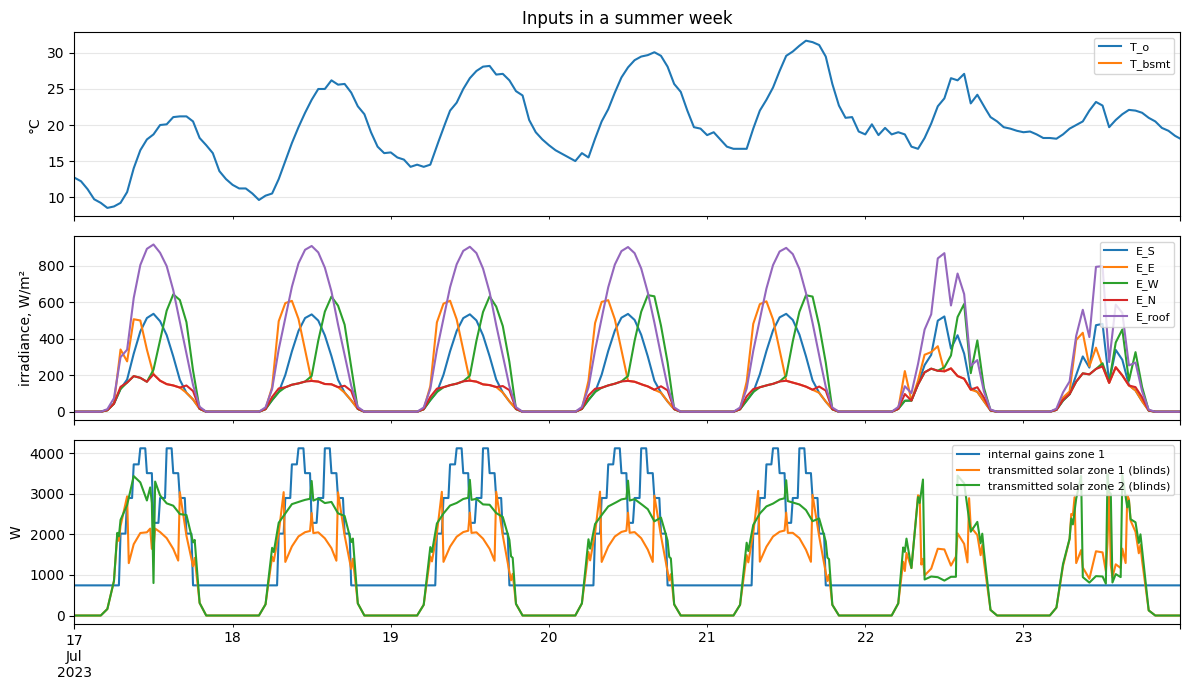

In [7]:
wk = slice(f'{year}-07-17', f'{year}-07-23')                     # a summer week (Monday to Sunday)
fig, axs = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
w.loc[wk, 'T_o'].plot(ax=axs[0], label='T_o')
axs[0].plot(t[(t >= '2023-07-17') & (t < '2023-07-24')], T_bsmt[(t >= '2023-07-17') & (t < '2023-07-24')],
            label='T_bsmt')
w.loc[wk].filter(like='E_').plot(ax=axs[1])
U.loc[wk, f'f: θ{air1} (Q̇occ + Q̇equip + Q̇light)'].plot(ax=axs[2], label='internal gains zone 1')
pd.Series(Q_sol[1], t).loc[wk].plot(ax=axs[2], label='transmitted solar zone 1 (blinds)')
pd.Series(Q_sol[2], t).loc[wk].plot(ax=axs[2], label='transmitted solar zone 2 (blinds)')
axs[0].set(ylabel='°C', title='Inputs in a summer week')
axs[1].set(ylabel='irradiance, W/m²')
axs[2].set(ylabel='W')
for ax in axs:
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3 Initial conditions

All states start at 20 °C at the beginning of the warm-up (as in 03CubicBuilding). After 30 days of warm-up the
influence of this choice is small: the largest time constant is 7.9 d with controller and 17.6 d without
(Assignment 3), and 20 °C is close to the real temperature of the concrete in December.

In [8]:
x0 = np.full(len(states), 20.0)

## 4 Integration in time

The gain $K_p$ of a zone is either $10^5$ W/K (controller on) or 0 (off), so there are four models; they are
discretised once with the implicit Euler method:

$$\theta_{C,k+1} = \Phi\,\theta_{C,k} + \Gamma u_k, \qquad \Phi = (I - \Delta t A_s)^{-1}, \quad
\Gamma = \Phi\,\Delta t B_s$$

The heat flow rate of the controller during a time step is $q_{HVAC} = K_p (T_{sp} - \theta_{air})$ with the air
temperature at the end of the step (implicit method). In the results, each time step has the air temperature at
its end and the heat flow rate during the step. The controller decides with the air temperature at the start of
the step (measurement).

The function `simulate` contains two controllers (the MPC follows in section 6):

- **P-controller** (as in Assignments 1–3): always on, set-point = heating set-point. It also cools as soon as the
  air is above the set-point.
- **dead-band**: per zone, on with $T_{sp} = T_h$ if the air is below $T_h$, on with $T_{sp} = T_c$ if it is above
  $T_c$, otherwise off (free-floating). This is the switching between models of tutorial 05SwitchModels.

In [9]:
K_on = 1e5                                                       # W/K, gain of the P-controller when on


def discrete(on1, on2, dt_=dt):
    """Implicit Euler model with the controller of zone 1 / zone 2 on (1) or off (0)."""
    G_K = G.copy()
    G_K[k_ctrl[0], k_ctrl[0]] = K_on * on1
    G_K[k_ctrl[1], k_ctrl[1]] = K_on * on2
    As, Bs, Cs, Ds = dm4bem.tc2ss(A, G_K, C, b_ptr, f_ptr, y_ptr)
    Phi = np.linalg.inv(np.eye(len(As)) - dt_ * As)
    return {'Phi': Phi, 'Gam': Phi @ (dt_ * Bs), 'Cs': Cs}


models = {(i, j): discrete(i, j) for i in (0, 1) for j in (0, 1)}
Cs = models[(0, 0)]['Cs']                                        # same in all models: the air nodes are states


def simulate(control, U, x0, k_start=0, k_end=None, mods=models, sched=None):
    """Simulation from step k_start to k_end. Returns y (air °C), q_HVAC (W) per zone and the states.

    sched = (T_h, T_c, occupied) on the time axis of U; default: the 15-min schedules."""
    T_h, T_c, occupied = sched or (globals()['T_h'], globals()['T_c'], globals()['occupied'])
    Ua = U.to_numpy()
    k_end = k_end or len(Ua)
    m_ = k_end - k_start
    y, q, X = np.zeros((m_, 2)), np.zeros((m_, 2)), np.zeros((m_, len(x0)))
    x = x0.copy()
    for i, k in enumerate(range(k_start, k_end)):
        X[i] = x
        θ_k = Cs @ x                                             # air at the start of the step (measurement)
        if control == 'P':
            on, sp = (1, 1), np.array([T_h[k], T_h[k]])
        else:                                                    # dead-band
            on, sp = [0, 0], np.array([T_h[k], T_h[k]])
            for j in range(2):
                if θ_k[j] < T_h[k]:
                    on[j], sp[j] = 1, T_h[k]
                elif θ_k[j] > T_c[k]:
                    on[j], sp[j] = 1, T_c[k]
            on = tuple(on)
        m = mods[on]
        u = Ua[k].copy()
        u[j_sp] = sp
        x = m['Phi'] @ x + m['Gam'] @ u
        y[i] = Cs @ x                                            # air at the end of the step
        q[i] = K_on * np.array(on) * (sp - y[i])
    return pd.DataFrame({'θ1': y[:, 0], 'θ2': y[:, 1], 'q1': q[:, 0], 'q2': q[:, 1],
                         'T_h': T_h[k_start:k_end], 'T_c': T_c[k_start:k_end],
                         'occupied': occupied[k_start:k_end]}, index=U.index[k_start:k_end]), X


res, X = {}, {}
for c in ('P', 'dead-band'):
    r, X[c] = simulate(c, U, x0)
    res[c] = r.iloc[k0:]                                          # without the warm-up
    X[c] = X[c][k0:]
print('simulated: ' + ', '.join(res))

simulated: P, dead-band


## 5 Results

In [10]:
S_tot = 2 * S_plan                                               # m², floor area of both zones


def key_figures(r):
    """Annual energy, peak loads and comfort of a simulation result."""
    q = r[['q1', 'q2']].to_numpy()
    θ = r[['θ1', 'θ2']].to_numpy()
    occ = r['occupied'].to_numpy()[:, None]
    under = np.clip(r[['T_h']].to_numpy() - 0.5 - θ, 0, None) * occ   # K below T_h - 0.5 K during occupancy
    over = np.clip(θ - r[['T_c']].to_numpy() - 0.5, 0, None) * occ     # K above T_c + 0.5 K
    hours = len(r) * dt / 3600
    return pd.Series({
        'heating, kWh': np.clip(q, 0, None).sum() * dt / 3.6e6,
        'cooling, kWh': -np.clip(q, None, 0).sum() * dt / 3.6e6,
        'heating, kWh/m²': np.clip(q, 0, None).sum() * dt / 3.6e6 / S_tot * 8760 / hours,
        'cooling, kWh/m²': -np.clip(q, None, 0).sum() * dt / 3.6e6 / S_tot * 8760 / hours,
        'peak heating (sum of zones), W/m²': q.max(axis=0).sum() / S_tot,
        'peak cooling (sum of zones), W/m²': -q.min(axis=0).sum() / S_tot,
        'under-heating, Kh': under.sum() * dt / 3600,
        'over-heating, Kh': over.sum() * dt / 3600})


fig_tab = pd.DataFrame({c: key_figures(r) for c, r in res.items()})
r = res['dead-band']
for j, name in ((1, 'zone 1 (south)'), (2, 'zone 2 (north)')):
    print(f'dead-band, {name}: heating {r[f"q{j}"].clip(lower=0).sum() * dt / 3.6e6 / S_plan:.1f} kWh/m², '
          f'cooling {-r[f"q{j}"].clip(upper=0).sum() * dt / 3.6e6 / S_plan:.1f} kWh/m²')
fig_tab.round(1)

dead-band, zone 1 (south): heating 3.9 kWh/m², cooling 25.0 kWh/m²
dead-band, zone 2 (north): heating 9.9 kWh/m², cooling 22.8 kWh/m²


,P,dead-band
"heating, kWh",5297.9,3103.9
"cooling, kWh",29558.9,10736.1
"heating, kWh/m²",11.8,6.9
"cooling, kWh/m²",65.7,23.9
"peak heating (sum of zones), W/m²",39.1,38.6
"peak cooling (sum of zones), W/m²",39.4,33.7
"under-heating, Kh",0.0,0.0
"over-heating, Kh",0.0,0.2


Two weeks with the dead-band controller and the P-controller: a winter week and a summer week (Monday to
Sunday). Grey band: between heating and cooling set-point.

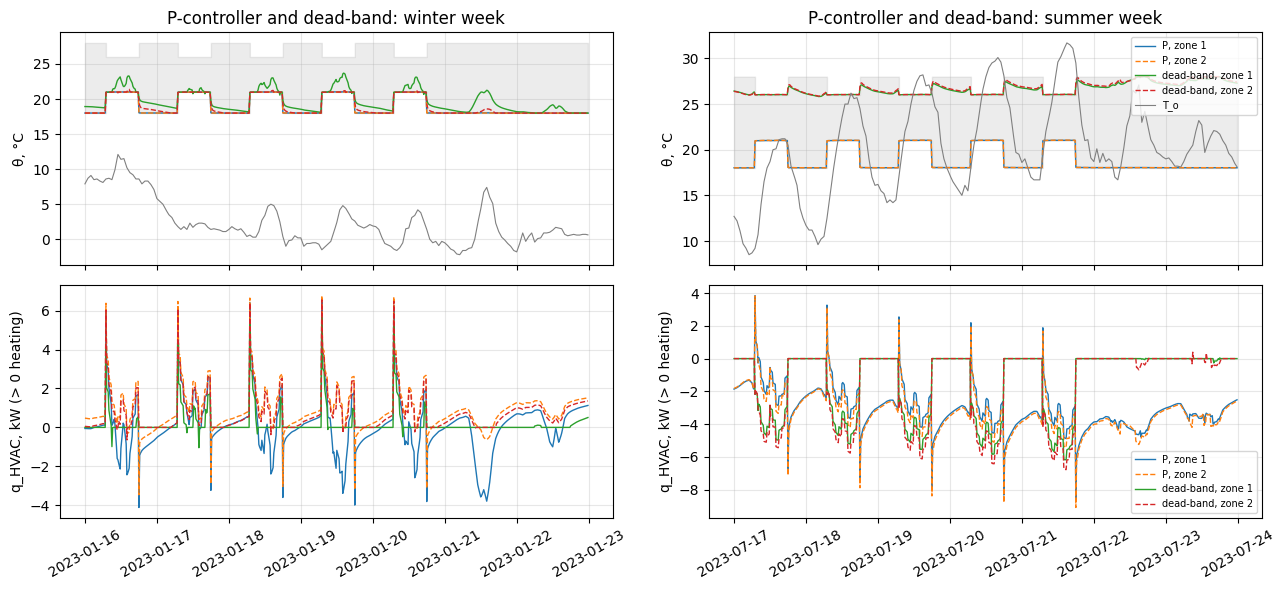

In [11]:
weeks = {'winter week': (f'{year}-01-16', f'{year}-01-22 23:45'),
         'summer week': (f'{year}-07-17', f'{year}-07-23 23:45')}


def plot_week(rs, title):
    """Air temperatures and q_HVAC of several results in one week."""
    fig, axs = plt.subplots(2, 2, figsize=(13, 6), sharex='col')
    for col, (wname, (a, b)) in enumerate(weeks.items()):
        for name, r in rs.items():
            r = r.loc[a:b]
            for j, ls in ((1, '-'), (2, '--')):
                axs[0, col].plot(r.index, r[f'θ{j}'], ls, lw=1, label=f'{name}, zone {j}')
                axs[1, col].plot(r.index, r[f'q{j}'] / 1000, ls, lw=1, label=f'{name}, zone {j}')
        r = next(iter(rs.values())).loc[a:b]
        axs[0, col].fill_between(r.index, r['T_h'], r['T_c'], color='grey', alpha=0.15, step='post')
        axs[0, col].plot(w.loc[a:b, 'T_o'], color='grey', lw=0.8, label='T_o')
        axs[0, col].set(title=f'{title}: {wname}', ylabel='θ, °C')
        axs[1, col].set(ylabel='q_HVAC, kW (> 0 heating)')
        axs[1, col].tick_params(axis='x', rotation=30)
    for ax in axs.flat:
        ax.grid(alpha=0.3)
    axs[0, 1].legend(fontsize=7, loc='upper right')
    axs[1, 1].legend(fontsize=7, loc='lower right')
    plt.tight_layout()
    plt.show()


plot_week(res, 'P-controller and dead-band')

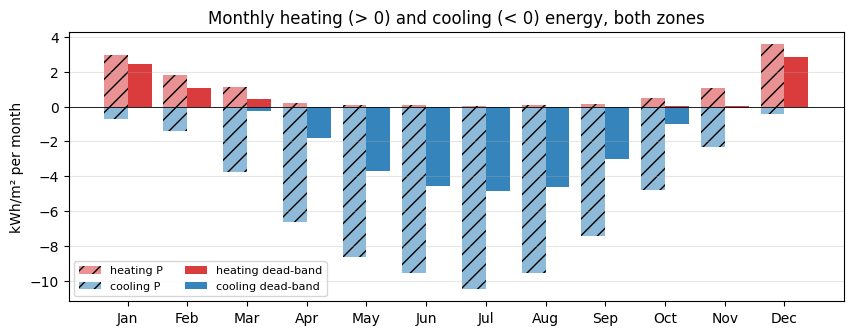

In [12]:
mon = pd.DataFrame({
    'heating P': res['P'][['q1', 'q2']].clip(lower=0).sum(axis=1),
    'cooling P': res['P'][['q1', 'q2']].clip(upper=0).sum(axis=1),
    'heating dead-band': res['dead-band'][['q1', 'q2']].clip(lower=0).sum(axis=1),
    'cooling dead-band': res['dead-band'][['q1', 'q2']].clip(upper=0).sum(axis=1),
}).resample('MS').sum() * dt / 3.6e6 / S_tot
fig, ax = plt.subplots(figsize=(10, 3.5))
x_m = np.arange(12)
for i, (col, color, hatch) in enumerate([('heating P', 'tab:red', '//'), ('cooling P', 'tab:blue', '//'),
                                         ('heating dead-band', 'tab:red', ''), ('cooling dead-band', 'tab:blue', '')]):
    ax.bar(x_m + (i // 2 - 0.5) * 0.4, mon[col], 0.4, color=color, alpha=0.5 if hatch else 0.9, hatch=hatch,
           label=col)
ax.set(xticks=x_m, xticklabels=mon.index.strftime('%b'), ylabel='kWh/m² per month',
       title='Monthly heating (> 0) and cooling (< 0) energy, both zones')
ax.axhline(0, color='k', lw=0.6)
ax.legend(fontsize=8, ncol=2)
ax.grid(axis='y', alpha=0.3)
plt.show()

**Time step.** The winter week and the summer week are simulated again with the dead-band controller and a
time step of 5 min (the states at the start of the week are taken from the annual simulation).

In [13]:
dt_f = 300
models_f = {key: discrete(*key, dt_=dt_f) for key in models}
U_f = U.resample(f'{dt_f}s').ffill()                              # inputs constant within 15 min
t_f = U_f.index
sched_f = tuple(pd.Series(v, t).reindex(t_f, method='ffill').to_numpy() for v in (T_h, T_c, occupied))
for wname, (a, b) in weeks.items():
    r15 = res['dead-band'].loc[a:b]
    ka, kb = t_f.get_loc(pd.Timestamp(a)), t_f.get_loc(pd.Timestamp(b)) + 1
    xa = X['dead-band'][res['dead-band'].index.get_loc(pd.Timestamp(a))]
    r5, _ = simulate('dead-band', U_f, xa, ka, kb, models_f, sched_f)
    e15 = r15[['q1', 'q2']].abs().sum().sum() * dt / 3.6e6
    e5 = r5[['q1', 'q2']].abs().sum().sum() * dt_f / 3.6e6
    print(f'{wname}: heating + cooling {e15:.1f} kWh (Δt = 15 min), {e5:.1f} kWh (Δt = 5 min), '
          f'difference {(e15 - e5) / e5:+.1%}; max |Δθ_air| = '
          f'{np.abs(r15["θ1"].values - r5["θ1"].resample(f"{dt}s").last().values[:len(r15)]).max():.2f} K')

winter week: heating + cooling 154.3 kWh (Δt = 15 min), 153.2 kWh (Δt = 5 min), difference +0.7%; max |Δθ_air| = 0.43 K
summer week: heating + cooling 493.3 kWh (Δt = 15 min), 493.1 kWh (Δt = 5 min), difference +0.0%; max |Δθ_air| = 0.19 K


## 6 Model predictive control (MPC)

The MPC uses the model without controller ($K_p = 0$) and calculates the heat flow rate $q_{HVAC}$ of each zone
directly; it is added to the flow-rate source of the air node. Every hour it solves a linear program over a
horizon of 24 h with a perfect forecast of all inputs (weather, gains, set-points). The heat flow rate is a
decision for every time step of 15 min in the first 4 h and for every hour after that (fewer variables); the air
temperature is checked at every time step:

$$\min \; \sum_h \left(q_{h} + q_{c}\right) \cdot 1\,\text{h} \; + \; \lambda \left(\hat q_h + \hat q_c\right)
\; + \; \rho \sum s$$

$$T_h - s \le \theta_{air} \le T_c + s, \qquad 0 \le q_h \le \hat q_h, \quad 0 \le q_c \le \hat q_c,
\quad q_h, q_c \le P_{max}, \qquad s \ge 0$$

with $q_{HVAC} = q_h - q_c$ (heating minus cooling) and $\hat q_h$, $\hat q_c$ the largest heating and cooling power
of each zone in the horizon. The air temperature is linear in $q$: $\theta_{air} = \theta_{free} + H q$, where
$\theta_{free}$ is the prediction with $q = 0$ and $H$ contains the responses of the air temperatures to the heat
flow rates, built from $C_s \Phi^m \Gamma_q$. The slack $s$ (penalty $\rho$ = 1000 kWh/K) keeps the problem
solvable. The power is limited to $P_{max}$ = 30 kW per zone (assumption, about 5 times the design heating load).
The first hour of the plan is applied, then the plan is calculated again (receding horizon).

Two variants:

- **MPC, energy** ($\lambda = 0$): minimum heating and cooling energy;
- **MPC, energy + peak** ($\lambda$ = 4 kWh per kW, assumption, e.g. a demand charge): the peak power also costs.

The MPC is run for the winter and the summer week, from the states of the dead-band simulation at the start of the
week.

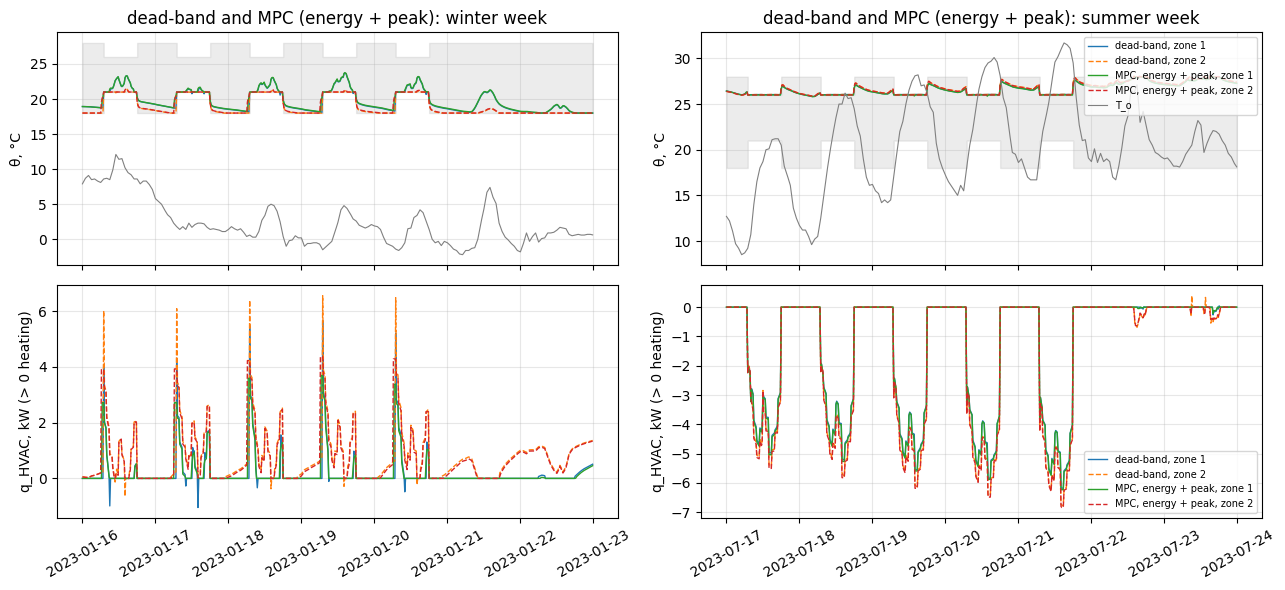

In [14]:
m0 = models[(0, 0)]
Phi0, Gam0 = m0['Phi'], m0['Gam']
j_q = [jf[air1], jf[air2]]                                       # inputs of the air nodes: q_HVAC is added here
N, P_max, rho = 96, 30e3, 1000.0                                 # horizon: 96 steps of 15 min = 24 h
block = np.r_[np.arange(16), 16 + (np.arange(16, N) - 16) // 4]  # decision of each step: 15 min for 4 h, then hourly
n_h = block.max() + 1                                            # number of decisions per zone
hours = np.bincount(block) * dt / 3600                           # h, duration of each decision

Hm, Pm = [], np.eye(len(states))                                 # Hm[m] = Cs Φ^m Γ_q (2 × 2)
for m in range(N):
    Hm.append(Cs @ Pm @ Gam0[:, j_q])
    Pm = Phi0 @ Pm
H = np.zeros((2 * N, 2 * N))                                     # air at the end of steps k … k+N-1 <- q
for r_ in range(N):
    for c_ in range(r_ + 1):
        H[2 * r_:2 * r_ + 2, 2 * c_:2 * c_ + 2] = Hm[r_ - c_]
E_h = np.zeros((2 * N, 2 * n_h))                                 # q of the time steps <- q of the decisions
for i in range(N):
    E_h[2 * i:2 * i + 2, 2 * block[i]:2 * block[i] + 2] = np.eye(2)
H_h = H @ E_h
n_v = 6 * n_h + 4                                                # variables: q_h, q_c, s (per decision, zone), peaks
Z = np.zeros((2 * N, 4))
A_comfort = np.block([[-H_h, H_h, -E_h, Z], [H_h, -H_h, -E_h, Z]])
A_peak = np.zeros((4 * n_h, n_v))                                # q_h - peak_h ≤ 0, q_c - peak_c ≤ 0
for i in range(2 * n_h):
    A_peak[i, i], A_peak[i, 6 * n_h + i % 2] = 1, -1
    A_peak[2 * n_h + i, 2 * n_h + i], A_peak[2 * n_h + i, 6 * n_h + 2 + i % 2] = 1, -1
A_ub = np.vstack([A_comfort, A_peak])
bounds = [(0, P_max)] * (4 * n_h) + [(0, None)] * (2 * n_h + 4)


def mpc(U, x0, k_start, k_end, lam):
    """MPC from step k_start to k_end with peak weight lam (kWh per kW). Returns the same table as simulate."""
    e = np.repeat(hours, 2) * 1e-3                               # kWh per W of each decision
    c_lp = np.r_[e, e, np.full(2 * n_h, rho), np.full(4, lam * 1e-3)]
    Ua = U.to_numpy()
    y, q = np.zeros((k_end - k_start, 2)), np.zeros((k_end - k_start, 2))
    x = x0.copy()
    for i0 in range(0, k_end - k_start, 4):
        k = k_start + i0
        xf, y_free = x.copy(), np.zeros(2 * N)                   # free prediction (q = 0)
        for m in range(N):
            xf = Phi0 @ xf + Gam0 @ Ua[min(k + m, len(Ua) - 1)]
            y_free[2 * m:2 * m + 2] = Cs @ xf
        kk = np.minimum(np.arange(k, k + N), len(Ua) - 1)        # set-points of the steps k … k+N-1
        lo, hi = np.repeat(T_h[kk], 2), np.repeat(T_c[kk], 2)
        sol = linprog(c_lp, A_ub=A_ub, b_ub=np.r_[y_free - lo, hi - y_free, np.zeros(4 * n_h)],
                      bounds=bounds, method='highs')
        plan = (sol.x[:2 * n_h] - sol.x[2 * n_h:4 * n_h]).reshape(n_h, 2)
        for m in range(min(4, k_end - k)):                        # apply the first hour of the plan
            u = Ua[k + m].copy()
            u[j_q] += plan[m]
            x = Phi0 @ x + Gam0 @ u
            y[i0 + m], q[i0 + m] = Cs @ x, plan[m]               # air at the end of the step, q during the step
    sl = slice(k_start, k_end)
    return pd.DataFrame({'θ1': y[:, 0], 'θ2': y[:, 1], 'q1': q[:, 0], 'q2': q[:, 1], 'T_h': T_h[sl], 'T_c': T_c[sl],
                         'occupied': occupied[sl]}, index=U.index[sl])


res_w = {'dead-band': [], 'MPC, energy': [], 'MPC, energy + peak': []}
for wname, (a, b) in weeks.items():
    ka, kb = t.get_loc(pd.Timestamp(a)), t.get_loc(pd.Timestamp(b)) + 1
    xa = X['dead-band'][res['dead-band'].index.get_loc(pd.Timestamp(a))]
    res_w['dead-band'].append(res['dead-band'].loc[a:b])
    res_w['MPC, energy'].append(mpc(U, xa, ka, kb, lam=0))
    res_w['MPC, energy + peak'].append(mpc(U, xa, ka, kb, lam=4))
res_w = {c: pd.concat(v) for c, v in res_w.items()}
plot_week({c: res_w[c] for c in ('dead-band', 'MPC, energy + peak')}, 'dead-band and MPC (energy + peak)')

In [15]:
tab_w = {}
for wname, (a, b) in weeks.items():
    for c, r in res_w.items():
        kf = key_figures(r.loc[a:b])
        tab_w[(wname, c)] = kf[['heating, kWh', 'cooling, kWh', 'peak heating (sum of zones), W/m²', 'peak cooling (sum of zones), W/m²',
                                'under-heating, Kh', 'over-heating, Kh']]
pd.DataFrame(tab_w).round(1)

winter week                                 \
                                    dead-band MPC, energy MPC, energy + peak   
heating, kWh                            153.1       154.1              162.2   
cooling, kWh                              1.2        -0.0               -0.0   
peak heating (sum of zones), W/m²        27.1        27.7               17.9   
peak cooling (sum of zones), W/m²         3.7        -0.0               -0.0   
under-heating, Kh                         0.0         0.0                0.0   
over-heating, Kh                          0.0         0.0                0.0   

                                  summer week                                 
                                    dead-band MPC, energy MPC, energy + peak  
heating, kWh                              0.2         0.0                0.0  
cooling, kWh                            493.1       497.5              497.7  
peak heating (sum of zones), W/m²         1.0         0.0                0.0  
peak cooling (sum of zones), W/m²        28.8        29.1               29.0  
under-heating, Kh                         0.0         0.0                0.0  
over-heating, Kh                          0.0         0.0                0.0

## 7 Discussion

**Inputs.** The south façade receives 1138 kWh/(m²·a), east 732, west 829, north 468 and the roof 1449. The
correction of the time of the sun changes the share between east and west strongly; the correction of the ground
reflection reduces the irradiance on the façades. The internal gains are 58.7 kWh/(m²·a).

**P-controller (model of Assignments 1–3).** With one set-point the controller heats and cools to the same
temperature: in summer it cools the building to 21 °C during occupancy and to 18 °C at night, in winter it cools
the south zone when the sun heats it above 21 °C. It needs 11.8 kWh/(m²·a) of heating and 65.7 kWh/(m²·a) of
cooling. One P-controller with a fixed set-point is useful for the steady state and the step response, not for a
year.

**Dead-band controller.** Heating 6.9 kWh/(m²·a) and cooling 23.9 kWh/(m²·a) (zone 1, south: 3.9 and 25.0; zone 2,
north: 9.9 and 22.8). For comparison, the standard values of SIA 2024 for room type 3.01 at the climate station
Chur are 8.1 kWh/(m²·a) heating and 12.4 kWh/(m²·a) cooling. The heating is close; the cooling is about twice the
standard value, because in this model

- the ventilation always has heat recovery (no summer bypass) and there is no night ventilation: at night the
  building stays at 26–27 °C although the outdoor air is often between 10 and 20 °C;
- the blinds close only above 200 W/m² on the façade; the north windows (60 % of the façade) are almost never
  shaded;
- all gains are convective on the air, and the air is cooled to 26 °C from 07:00 without pre-cooling.

The peak heating load is 38.6 W/m², higher than the steady-state design load of 24.6 W/m² (Assignment 2), because
the set-point jumps from 18 °C to 21 °C at 07:00 and the controller (unlimited power) re-heats within about one
time step. In the winter week the sun heats the south zone above 21 °C (free-floating up to about 24 °C) while the north
zone needs heating; the interior wall transfers part of this heat. In the summer week the north zone needs more
cooling than the south zone, because its blinds stay open.

**Time step.** With 5 min instead of 15 min the heating and cooling energy changes by less than 1 %; the air
temperature differs by up to 0.4 K at the moments when the set-point or the controller switches.

**MPC.** With a perfect forecast and only the energy as cost, the MPC needs the same energy as the dead-band
controller (within 1 %): heating as late as possible and keeping the air exactly at the limit is already what the
dead-band controller does. Its advantage appears when the cost has another term: with the peak power in the cost
(demand charge, 4 kWh per kW) it starts heating earlier in the morning, using the thermal mass, and reduces the peak
heating load in the winter week by 34 % (27.1 to 17.9 W/m²) for about 6 % more heating energy. The peak in the
cost covers only the current horizon of 24 h; a real demand charge over a month would need the peak already reached
as an additional constraint. In the summer week it
does not reduce the cooling peak: the peak is in the afternoon of occupied days, and pre-cooling the concrete would
cost more cooling energy than the penalty saves; free night ventilation (not modelled) would be the better measure.

In the dead-band controller the P-controller of the active mode is symmetric: in heating mode it can extract a
little heat within a time step if the gains push the air above $T_h$ (and vice versa). Over the year this is 19 kWh
of cooling and 10 kWh of heating; it is the small cooling in the winter week and the small heating in the summer
week of the dead-band controller.

**Limits.** Ideal controllers (dead-band without power limit, MPC with 30 kW and perfect forecast), sensible heat
only, convective internal gains, no night ventilation and no bypass of the heat recovery, one typical weather year (the weather values are placed at the start of their hour and interpolated, so they
are about half an hour early),
the hypotheses of Assignment 1 (e.g. star network for long-wave radiation, constant coefficients).